# Chapitre 8 - Lab : niveaux d'isolation réels de PostgreSQL

Les cours 2 à 4 ont rejoué les anomalies sur un mini-moteur. Ce lab les reproduit sur un
vrai système, PostgreSQL 16, avec deux connexions (ou plus) qui s'entrelacent : lectures
sales impossibles, lecture biaisée en `READ COMMITTED`, versions MVCC visibles
(`xmin`, `xmax`, `ctid`, pages brutes), mises à jour perdues et leurs remèdes, write skew
des médecins de garde, fantôme de la réservation de salle, échecs de sérialisation
(`SQLSTATE 40001`) et interblocages (`40P01`).

**Démarrer et arrêter PostgreSQL** (depuis la racine du dépôt) :

```bash
docker compose -f docker/transactions/compose.yml -p ddia_transactions up -d
# ... exécuter le notebook ...
docker compose -f docker/transactions/compose.yml -p ddia_transactions down -v
```

Le conteneur écoute sur le port **10832** de l'hôte (utilisateur, mot de passe et base :
`ddia`).

**Plan.**

1. Pas de lecture sale, même en `READ UNCOMMITTED`.
2. Lecture biaisée en `READ COMMITTED`, instantané en `REPEATABLE READ`.
3. MVCC sous le capot : `xmin`, `xmax`, pages brutes et `VACUUM`.
4. Mises à jour perdues : le problème et quatre remèdes, sous charge.
5. Write skew : les médecins de garde.
6. Fantôme : la réservation de salle.
7. Interblocage détecté.

In [1]:
import threading
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg import errors

from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
DSN = "host=localhost port=10832 user=ddia password=ddia dbname=ddia connect_timeout=5"
NIVEAUX = {"RC": "READ COMMITTED", "RR": "REPEATABLE READ", "SER": "SERIALIZABLE", "RU": "READ UNCOMMITTED"}

with psycopg.connect(DSN, autocommit=True) as c:
    print(c.execute("SELECT version()").fetchone()[0])


def session(niveau="RC"):
    """Nouvelle connexion dont chaque transaction démarre au niveau demandé."""
    c = psycopg.connect(DSN)
    c.execute(f"SET SESSION CHARACTERISTICS AS TRANSACTION ISOLATION LEVEL {NIVEAUX[niveau]}")
    c.commit()
    return c


def admin(sql, params=None):
    with psycopg.connect(DSN, autocommit=True) as c:
        cur = c.execute(sql, params)
        return cur.fetchall() if cur.description else None


def en_fond(fn, *args):
    """Exécute une instruction qui risque de bloquer dans un fil séparé (renvoie un Future)."""
    ex = ThreadPoolExecutor(max_workers=1)
    fut = ex.submit(fn, *args)
    ex.shutdown(wait=False)
    return fut

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (Alpine 15.2.0) 15.2.0, 64-bit


## 1. Pas de lecture sale, même en `READ UNCOMMITTED` (section *No dirty reads*)

PostgreSQL accepte le niveau `READ UNCOMMITTED` du standard mais le traite comme `READ
COMMITTED` : grâce à MVCC, il n'a aucune raison de montrer une version non validée.
Vérifions : A modifie un prix sans valider, B le lit dans chacun des deux niveaux.

In [2]:
admin("DROP TABLE IF EXISTS produits; CREATE TABLE produits (id int PRIMARY KEY, prix int);"
      "INSERT INTO produits VALUES (1, 20)")
a = session("RC")
a.execute("UPDATE produits SET prix = 25 WHERE id = 1")          # non validé
lignes = []
for niv in ["RU", "RC"]:
    b = session(niv)
    lu = b.execute("SELECT prix FROM produits WHERE id = 1").fetchone()[0]
    b.commit(); b.close()
    lignes.append(dict(niveau_de_B=NIVEAUX[niv], prix_lu_par_B=lu))
a.rollback(); a.close()
pd.DataFrame(lignes)

,niveau_de_B,prix_lu_par_B
0,READ UNCOMMITTED,20
1,READ COMMITTED,20


Dans les deux cas, B lit 20 : l'écriture non validée de A reste invisible. Le standard
SQL autorise un niveau à être **plus fort** que demandé, et PostgreSQL en profite.

> **À retenir.** Dans PostgreSQL, il n'existe pas de lecture sale : `READ UNCOMMITTED` est
> un synonyme de `READ COMMITTED`.

## 2. Lecture biaisée et instantané (section *Snapshot Isolation and Repeatable Read*)

Inès consulte ses deux comptes (500 € chacun) pendant qu'un virement de 100 € s'exécute
entre sa première et sa seconde lecture. On rejoue l'entrelacement exactement, avec deux
connexions, dans les deux niveaux.

In [3]:
def scenario_lecture_biaisee(niveau):
    admin("DROP TABLE IF EXISTS comptes; CREATE TABLE comptes (id int PRIMARY KEY, solde int);"
          "INSERT INTO comptes VALUES (1, 500), (2, 500)")
    ines, vir = session(niveau), session("RC")
    c1 = ines.execute("SELECT solde FROM comptes WHERE id = 1").fetchone()[0]
    vir.execute("UPDATE comptes SET solde = solde - 100 WHERE id = 2")
    vir.execute("UPDATE comptes SET solde = solde + 100 WHERE id = 1")
    vir.commit()
    c2 = ines.execute("SELECT solde FROM comptes WHERE id = 2").fetchone()[0]
    c1_bis = ines.execute("SELECT solde FROM comptes WHERE id = 1").fetchone()[0]
    ines.commit(); ines.close(); vir.close()
    return dict(niveau=NIVEAUX[niveau], compte1=c1, compte2=c2, total_vu=c1 + c2, compte1_relu=c1_bis)


pd.DataFrame([scenario_lecture_biaisee("RC"), scenario_lecture_biaisee("RR")]).set_index("niveau")

,compte1,compte2,total_vu,compte1_relu
niveau,,,,
READ COMMITTED,500,400,900,600
REPEATABLE READ,500,500,1000,500


En `READ COMMITTED`, chaque **instruction** prend un nouvel instantané : Inès voit 900 €,
et relire le compte 1 donne une autre valeur (lecture non répétable). En `REPEATABLE
READ` (la snapshot isolation de PostgreSQL), l'instantané est pris à la **première
instruction** de la transaction et figé : 1 000 €, et la relecture donne la même valeur.

> **À retenir.** `READ COMMITTED` = un instantané par instruction ; `REPEATABLE READ` = un
> instantané par transaction.

## 3. MVCC sous le capot : `xmin`, `xmax`, pages brutes et `VACUUM` (section *Multiversion concurrency control*)

Chaque ligne de PostgreSQL porte des colonnes système : `xmin` (transaction qui a créé
cette version), `xmax` (transaction qui l'a supprimée ou remplacée, 0 sinon) et `ctid`
(position physique : page, emplacement). Une mise à jour crée une **nouvelle version** à
un autre emplacement. L'extension `pageinspect` montre aussi les versions mortes.

In [4]:
admin("CREATE EXTENSION IF NOT EXISTS pageinspect")
admin("DROP TABLE IF EXISTS mvcc; CREATE TABLE mvcc (id int PRIMARY KEY, v int) WITH (autovacuum_enabled = off);"
      "INSERT INTO mvcc VALUES (1, 100)")
for nouvelle in [200, 300]:
    admin("UPDATE mvcc SET v = %s WHERE id = 1", (nouvelle,))
print("version visible :", admin("SELECT xmin, xmax, ctid, v FROM mvcc"))


def page():
    return pd.DataFrame(admin("SELECT lp, t_xmin, t_xmax, t_ctid, "
                              "CASE WHEN t_xmax = '0' THEN 'vivante' ELSE 'morte' END "
                              "FROM heap_page_items(get_raw_page('mvcc', 0))"),
                        columns=["emplacement", "xmin", "xmax", "ctid suivant", "état"])


page()

version visible : [('12080', '0', '(0,3)', 300)]


,emplacement,xmin,xmax,ctid suivant,état
0,1,12078,12079,"(0,2)",morte
1,2,12079,12080,"(0,3)",morte
2,3,12080,0,"(0,3)",vivante


La page contient trois versions physiques de la même ligne : les deux premières ont un
`xmax` (elles ont été remplacées) et pointent vers la version suivante (`ctid`), la
dernière est vivante. C'est la chaîne de versions du cours 2.

**Une transaction longue empêche le nettoyage.** Ouvrons une transaction `REPEATABLE
READ` qui lit la ligne, faisons 20 mises à jour, puis lançons `VACUUM` : les versions
mortes créées après le début de la transaction longue ne peuvent pas être supprimées.

la transaction longue lit toujours : 300


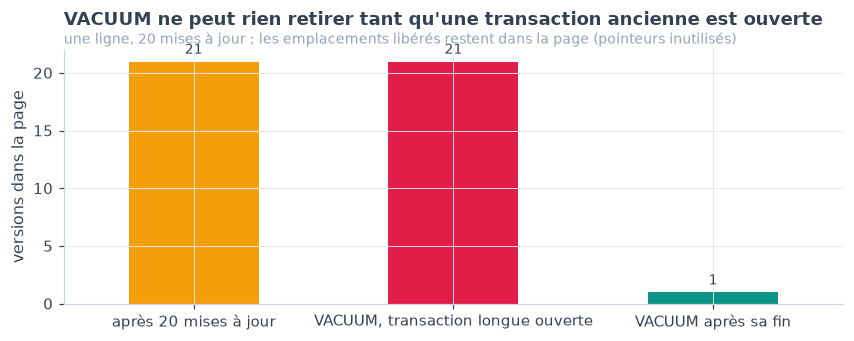

,versions_physiques,vivantes
après 20 mises à jour,21,1
"VACUUM, transaction longue ouverte",21,1
VACUUM après sa fin,1,1


In [5]:
admin("VACUUM mvcc")
longue = session("RR")
longue.execute("SELECT v FROM mvcc WHERE id = 1").fetchone()
for i in range(20):
    admin("UPDATE mvcc SET v = %s WHERE id = 1", (1000 + i,))


def compte_versions():
    p = page()
    return dict(versions_physiques=len(p.dropna(subset=["xmin"])), vivantes=int((p["état"] == "vivante").sum()))


etapes = {"après 20 mises à jour": compte_versions()}
admin("VACUUM mvcc")
etapes["VACUUM, transaction longue ouverte"] = compte_versions()
print("la transaction longue lit toujours :", longue.execute("SELECT v FROM mvcc WHERE id = 1").fetchone()[0])
longue.commit(); longue.close()
admin("VACUUM mvcc")
etapes["VACUUM après sa fin"] = compte_versions()
vac = pd.DataFrame(etapes).T
ax = vac["versions_physiques"].plot.bar(figsize=(8, 3.2), color=[AMBER, ROSE, TEAL], rot=0)
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("versions dans la page")
ax.set_title("VACUUM ne peut rien retirer tant qu'une transaction ancienne est ouverte")
subtitle(ax, "une ligne, 20 mises à jour ; les emplacements libérés restent dans la page (pointeurs inutilisés)")
plt.tight_layout(); plt.show()
vac

Pendant que la transaction longue est ouverte, `VACUUM` conserve toutes les versions
(elle pourrait en avoir besoin selon l'horizon de PostgreSQL), et elle continue de lire
la valeur de son instantané. Une fois terminée, `VACUUM` retire toutes les versions
mortes. C'est le gonflement de table mesuré à l'exercice 8.3.

> **À retenir.** Dans PostgreSQL, une mise à jour écrit une nouvelle version ; les
> anciennes ne disparaissent qu'au `VACUUM`, et seulement si aucune transaction ouverte
> ne peut encore les voir.

## 4. Mises à jour perdues : le problème et quatre remèdes (section *Preventing Lost Updates*)

D'abord l'entrelacement exact de deux incréments lire-modifier-écrire.

In [6]:
def deux_increments(niveau):
    admin("DROP TABLE IF EXISTS compteur; CREATE TABLE compteur (id int PRIMARY KEY, v int);"
          "INSERT INTO compteur VALUES (1, 42)")
    a, b = session(niveau), session(niveau)
    va = a.execute("SELECT v FROM compteur WHERE id = 1").fetchone()[0]
    vb = b.execute("SELECT v FROM compteur WHERE id = 1").fetchone()[0]
    a.execute("UPDATE compteur SET v = %s WHERE id = 1", (va + 1,))
    a.commit()
    try:
        b.execute("UPDATE compteur SET v = %s WHERE id = 1", (vb + 1,))
        b.commit()
        issue_b = "validée"
    except errors.SerializationFailure as e:
        b.rollback()
        issue_b = f"échec {e.sqlstate} : {str(e).splitlines()[0]}"
    a.close(); b.close()
    return dict(niveau=NIVEAUX[niveau], issue_B=issue_b, valeur_finale=admin("SELECT v FROM compteur")[0][0])


pd.DataFrame([deux_increments("RC"), deux_increments("RR")]).set_index("niveau")

,issue_B,valeur_finale
niveau,,
READ COMMITTED,validée,43
REPEATABLE READ,échec 40001 : could not serialize access due t...,43


En `READ COMMITTED`, B écrase l'incrément de A (43). En `REPEATABLE READ`, PostgreSQL
détecte que la ligne a été modifiée par une transaction concurrente depuis l'instantané
de B et renvoie l'erreur `40001` (*could not serialize access due to concurrent
update*) : à l'application de réessayer.

**Sous charge.** 8 fils font chacun 40 incréments, selon quatre stratégies ; on compte les
incréments perdus et les réessais.

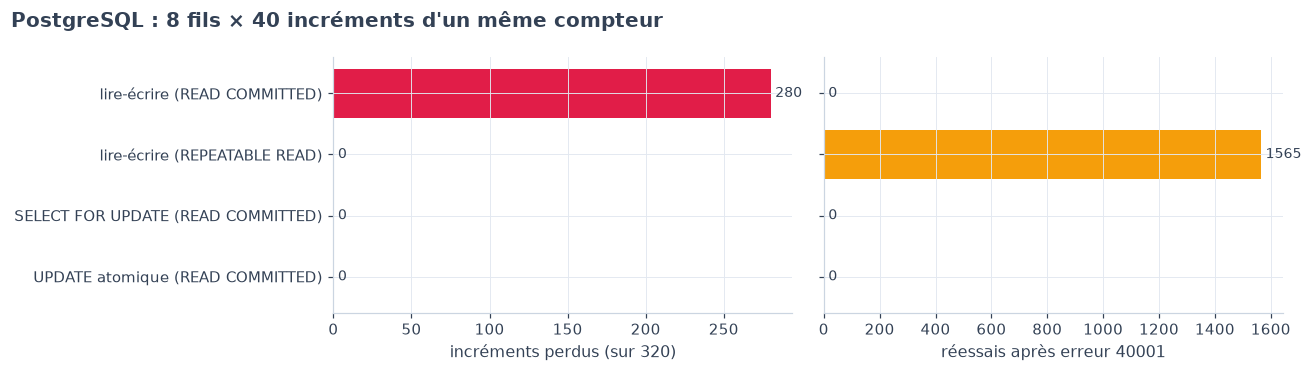

,attendu,obtenu,perdus,réessais,durée_s
stratégie,,,,,
lire-écrire (READ COMMITTED),320,40,280,0,0.08
lire-écrire (REPEATABLE READ),320,320,0,1565,0.34
SELECT FOR UPDATE (READ COMMITTED),320,320,0,0,0.28
UPDATE atomique (READ COMMITTED),320,320,0,0,0.07


In [7]:
def stress(strategie, n_fils=8, n_incr=40):
    admin("DROP TABLE IF EXISTS compteur; CREATE TABLE compteur (id int PRIMARY KEY, v int);"
          "INSERT INTO compteur VALUES (1, 0)")
    reessais = [0] * n_fils

    def travail(i):
        c = session("RR" if strategie == "lire-écrire (REPEATABLE READ)" else "RC")
        for _ in range(n_incr):
            while True:
                try:
                    if strategie == "UPDATE atomique (READ COMMITTED)":
                        c.execute("UPDATE compteur SET v = v + 1 WHERE id = 1")
                    else:
                        verrou = " FOR UPDATE" if "FOR UPDATE" in strategie else ""
                        v = c.execute(f"SELECT v FROM compteur WHERE id = 1{verrou}").fetchone()[0]
                        time.sleep(0.0005)                      # un peu de logique applicative
                        c.execute("UPDATE compteur SET v = %s WHERE id = 1", (v + 1,))
                    c.commit()
                    break
                except errors.SerializationFailure:
                    c.rollback()
                    reessais[i] += 1
        c.close()

    t0 = time.perf_counter()
    with ThreadPoolExecutor(n_fils) as ex:
        list(ex.map(travail, range(n_fils)))
    duree = time.perf_counter() - t0
    final = admin("SELECT v FROM compteur")[0][0]
    return dict(stratégie=strategie, attendu=n_fils * n_incr, obtenu=final,
                perdus=n_fils * n_incr - final, réessais=sum(reessais), durée_s=round(duree, 2))


strategies = ["lire-écrire (READ COMMITTED)", "lire-écrire (REPEATABLE READ)",
              "SELECT FOR UPDATE (READ COMMITTED)", "UPDATE atomique (READ COMMITTED)"]
charge = pd.DataFrame([stress(s) for s in strategies]).set_index("stratégie")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
cols = [ROSE, AMBER, SKY, TEAL]
axes[0].barh(charge.index, charge["perdus"], color=cols)
axes[0].set_xlabel("incréments perdus (sur 320)")
axes[1].barh(charge.index, charge["réessais"], color=cols)
axes[1].set_xlabel("réessais après erreur 40001")
axes[1].set_yticklabels([])
for ax in axes:
    ax.invert_yaxis()
    annotate_bars(ax, "{:.0f}")
finish(fig, "PostgreSQL : 8 fils × 40 incréments d'un même compteur")
plt.show()
charge

Les chiffres exacts varient d'une exécution à l'autre (vrai parallélisme), mais le
tableau est toujours le même : le cycle lire-écrire en `READ COMMITTED` perd une grande
partie des incréments ; en `REPEATABLE READ` il n'en perd aucun mais multiplie les
réessais ; `SELECT ... FOR UPDATE` et l'`UPDATE` atomique ne perdent rien et ne réessaient
jamais, l'`UPDATE` atomique étant le plus simple (et en général le plus rapide).

> **À retenir.** Dans PostgreSQL : `UPDATE ... SET v = v + 1` ou `FOR UPDATE` en `READ
> COMMITTED`, ou `REPEATABLE READ` avec une boucle de réessai sur `40001`.

## 5. Write skew : les médecins de garde (section *Write Skew and Phantoms*)

Alice et Bruno sont de garde ; chacun vérifie qu'au moins deux médecins le sont, puis se
retire. Entrelacement : les deux vérifient, puis les deux écrivent et valident.

In [8]:
def medecins(niveau, for_update=False):
    admin("DROP TABLE IF EXISTS medecins; CREATE TABLE medecins (nom text PRIMARY KEY, de_garde bool);"
          "INSERT INTO medecins VALUES ('alice', true), ('bruno', true)")
    a, b = session(niveau), session(niveau)
    fu = " FOR UPDATE" if for_update else ""
    q = f"SELECT count(*) FROM (SELECT nom FROM medecins WHERE de_garde{fu}) s"
    issues = {}
    na = a.execute(q).fetchone()[0]
    if for_update:
        fut = en_fond(lambda: b.execute(q).fetchone()[0])       # B attend le verrou de A
        time.sleep(0.3)
        if na >= 2:
            a.execute("UPDATE medecins SET de_garde = false WHERE nom = 'alice'")
        a.commit(); issues["A"] = "validée"
        nb = fut.result()
    else:
        nb = b.execute(q).fetchone()[0]
        if na >= 2:
            a.execute("UPDATE medecins SET de_garde = false WHERE nom = 'alice'")
    try:
        if nb >= 2:
            b.execute("UPDATE medecins SET de_garde = false WHERE nom = 'bruno'")
        if not for_update:
            a.commit(); issues["A"] = "validée"
        b.commit(); issues["B"] = "validée"
    except errors.SerializationFailure as e:
        b.rollback(); issues["B"] = f"échec {e.sqlstate}"
    a.close(); b.close()
    reste = admin("SELECT count(*) FROM medecins WHERE de_garde")[0][0]
    return dict(configuration=f"{NIVEAUX[niveau]}{' + FOR UPDATE' if for_update else ''}",
                B_a_compté=nb, issue_A=issues.get("A"), issue_B=issues.get("B"), médecins_de_garde=reste)


pd.DataFrame([medecins("RC"), medecins("RR"), medecins("RC", for_update=True),
              medecins("SER")]).set_index("configuration")

,B_a_compté,issue_A,issue_B,médecins_de_garde
configuration,,,,
READ COMMITTED,2,validée,validée,0
REPEATABLE READ,2,validée,validée,0
READ COMMITTED + FOR UPDATE,1,validée,validée,1
SERIALIZABLE,2,validée,échec 40001,1


- En `READ COMMITTED` et en `REPEATABLE READ`, les deux transactions valident et **plus
  personne n'est de garde** : la snapshot isolation de PostgreSQL ne détecte pas le write
  skew (elle ne détecte que les écritures sur la **même** ligne).
- Avec `FOR UPDATE`, B attend le verrou d'Alice, puis PostgreSQL réévalue la condition
  sur la dernière version validée : B ne compte plus qu'un médecin et ne se retire pas.
- En `SERIALIZABLE` (SSI), la validation de B échoue avec `40001` : sa prémisse a été
  modifiée par A.

> **À retenir.** Le write skew passe en `REPEATABLE READ` ; il faut `SERIALIZABLE` ou un
> verrouillage explicite des lignes lues.

## 6. Fantôme : la réservation de salle (section *Phantoms causing write skew*)

Deux personnes réservent la salle 1 de midi à 13 h : chacune vérifie qu'aucune
réservation ne chevauche le créneau, puis insère la sienne.

In [9]:
def reservation(niveau, for_update=False):
    admin("DROP TABLE IF EXISTS resas; CREATE TABLE resas (id serial PRIMARY KEY, salle int,"
          " debut timestamp, fin timestamp, qui text)")
    a, b = session(niveau), session(niveau)
    fu = " FOR UPDATE" if for_update else ""
    q = ("SELECT count(*) FROM (SELECT id FROM resas WHERE salle = 1 AND fin > '2025-01-01 12:00'"
         f" AND debut < '2025-01-01 13:00'{fu}) s")
    ins = "INSERT INTO resas (salle, debut, fin, qui) VALUES (1, '2025-01-01 12:00', '2025-01-01 13:00', %s)"
    na, nb = a.execute(q).fetchone()[0], b.execute(q).fetchone()[0]
    issues = {}
    for nom, c, n in [("A", a, na), ("B", b, nb)]:
        try:
            if n == 0:
                c.execute(ins, (nom,))
            c.commit(); issues[nom] = "validée"
        except errors.SerializationFailure as e:
            c.rollback(); issues[nom] = f"échec {e.sqlstate}"
    a.close(); b.close()
    return dict(configuration=f"{NIVEAUX[niveau]}{' + FOR UPDATE' if for_update else ''}",
                issue_A=issues["A"], issue_B=issues["B"], réservations=admin("SELECT count(*) FROM resas")[0][0])


pd.DataFrame([reservation("RR"), reservation("RC", for_update=True), reservation("SER")]).set_index("configuration")

,issue_A,issue_B,réservations
configuration,,,
REPEATABLE READ,validée,validée,2
READ COMMITTED + FOR UPDATE,validée,validée,2
SERIALIZABLE,validée,échec 40001,1


`FOR UPDATE` ne sert à rien : la recherche ne trouve aucune ligne, il n'y a rien à
verrouiller, et la salle est réservée deux fois. En `SERIALIZABLE`, PostgreSQL enregistre
la **lecture du prédicat** (verrous SIREAD sur les pages d'index ou de table) : la seconde
validation échoue. (Une contrainte d'exclusion `EXCLUDE USING gist` sur les intervalles
serait une autre solution, propre à PostgreSQL.)

> **À retenir.** Les fantômes exigent `SERIALIZABLE` (ou une contrainte qui exprime
> l'invariant, ou des conflits matérialisés).

## 7. Interblocage détecté (section *Explicit locking*)

Deux transactions verrouillent deux lignes dans l'ordre inverse. PostgreSQL attend
`deadlock_timeout` (réglé à 200 ms dans le `compose.yml`), détecte le cycle et abandonne
l'une des deux avec l'erreur `40P01`. On trace la chronologie mesurée.

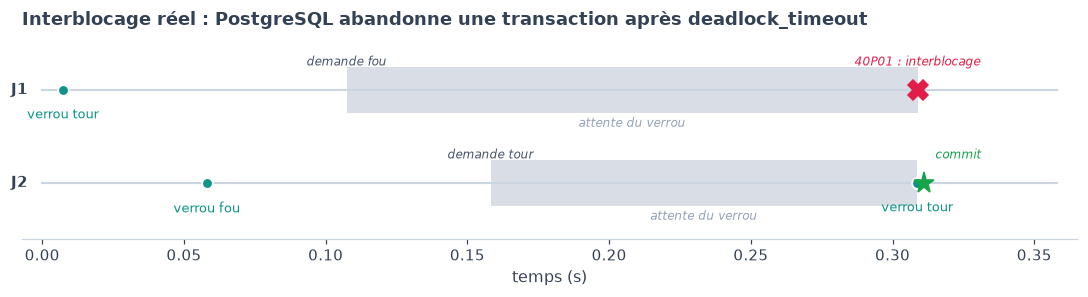

,session,t_s,événement
0,J1,0.007276,verrou tour
1,J2,0.058032,verrou fou
2,J1,0.107408,demande fou
3,J2,0.158160,demande tour
4,J2,0.308634,verrou tour
5,J1,0.308790,40P01 interblocage
6,J2,0.311221,commit


In [10]:
admin("DROP TABLE IF EXISTS pieces; CREATE TABLE pieces (nom text PRIMARY KEY, pos text);"
      "INSERT INTO pieces VALUES ('tour', 'a1'), ('fou', 'c1')")
t0 = time.perf_counter()
chrono = []


def note(qui, quoi):
    chrono.append((qui, time.perf_counter() - t0, quoi))


j1, j2 = session("RC"), session("RC")


def etape_j1():
    try:
        j1.execute("SELECT * FROM pieces WHERE nom = 'tour' FOR UPDATE"); note("J1", "verrou tour")
        time.sleep(0.1)
        note("J1", "demande fou")
        j1.execute("SELECT * FROM pieces WHERE nom = 'fou' FOR UPDATE"); note("J1", "verrou fou")
        j1.commit(); note("J1", "commit")
    except errors.DeadlockDetected:
        j1.rollback(); note("J1", "40P01 interblocage")


def etape_j2():
    try:
        time.sleep(0.05)
        j2.execute("SELECT * FROM pieces WHERE nom = 'fou' FOR UPDATE"); note("J2", "verrou fou")
        time.sleep(0.1)
        note("J2", "demande tour")
        j2.execute("SELECT * FROM pieces WHERE nom = 'tour' FOR UPDATE"); note("J2", "verrou tour")
        j2.commit(); note("J2", "commit")
    except errors.DeadlockDetected:
        j2.rollback(); note("J2", "40P01 interblocage")


f1, f2 = en_fond(etape_j1), en_fond(etape_j2)
f1.result(); f2.result()
j1.close(); j2.close()
chrono_df = pd.DataFrame(chrono, columns=["session", "t_s", "événement"]).sort_values("t_s")
st = SpaceTime(["J1", "J2"], t_max=chrono_df["t_s"].max() * 1.15, width=10, time_label="temps (s)")
st.ax.set_title("Interblocage réel : PostgreSQL abandonne une transaction après deadlock_timeout", pad=6)
for sess, g_ in chrono_df.groupby("session"):
    evts = list(g_.itertuples())
    for k, e in enumerate(evts):
        if e.événement.startswith("demande") and k + 1 < len(evts):
            st.span(sess, e.t_s, evts[k + 1].t_s, "attente du verrou", color=GRAY, alpha=0.35)
            st.note(e.t_s, sess, e.événement, dy=0.3, fontsize=8)
        elif "40P01" in e.événement:
            st.event(sess, e.t_s, "", kind="crash")
            st.note(e.t_s, sess, "40P01 : interblocage", dy=0.3, color=ROSE, fontsize=8)
        elif e.événement == "commit":
            st.event(sess, e.t_s, "", kind="star", color=GREEN)
            st.note(e.t_s + 0.012, sess, "commit", dy=0.3, color=GREEN, fontsize=8)
        else:
            st.event(sess, e.t_s, e.événement, kind="point")
st.show()
chrono_df

L'une des transactions obtient ses deux verrous et valide ; l'autre reçoit `40P01`
environ 200 ms après le début de l'attente (la valeur de `deadlock_timeout`). Le remède
applicatif : verrouiller toujours dans le même ordre, et réessayer sur `40P01` comme sur
`40001`.

> **À retenir.** Les interblocages sont détectés automatiquement mais coûtent un délai et
> une transaction à refaire.

## Synthèse

| anomalie | `READ COMMITTED` | `REPEATABLE READ` | `SERIALIZABLE` |
|---|---|---|---|
| lecture sale | empêchée (même en `READ UNCOMMITTED`) | empêchée | empêchée |
| lecture biaisée | **possible** | empêchée (instantané) | empêchée |
| mise à jour perdue | **possible** | empêchée (erreur 40001) | empêchée (erreur 40001) |
| write skew | **possible** | **possible** | empêchée (erreur 40001) |
| fantôme (write skew) | **possible** | **possible** | empêchée (erreur 40001) |

PostgreSQL implémente la snapshot isolation sous le nom `REPEATABLE READ` et SSI sous le
nom `SERIALIZABLE` ; dans les deux cas, l'application doit savoir **réessayer** une
transaction abandonnée. Pensez à arrêter le conteneur :

```bash
docker compose -f docker/transactions/compose.yml -p ddia_transactions down -v
```